# NOVA B09 · Paper tables and figures

Collects the results of NovaLM (B05, B06) and Granite (B08) and generates the LaTeX tables, figures and the list of headline numbers used in the paper.

## Dependencies
Python packages required by this notebook in addition to PyTorch.

In [1]:
!pip install -q pandas matplotlib jinja2

## Table and figure generator (`make_figures.py`)
Reads each results folder and writes the AUROC ladder, significance, repair, closed-form and benchmark tables as LaTeX, the comparison figures as PNG (and PDF where available), and `headline_numbers.md`.

In [2]:
%%writefile make_figures.py
"""
Team NOVA - AFML Project
make_figures.py: turn the experiment folders into publication tables (LaTeX) and figures (PDF/PNG) for the
ICML-style paper, plus headline_numbers.md with every number quoted in the abstract.

Usage (after notebooks 05, 06, 08):
  python make_figures.py --out_dir PAPER \
     --runs "Small (13.8M)=/content/drive/MyDrive/nova/results/exp_moe" \
            "Base (88M)=/content/drive/MyDrive/nova_base/results/exp_moe" \
            "Granite (1.3B)=/content/drive/MyDrive/nova_base/results/exp_granite" \
     --bench .../results/benchmarks.csv .../results/bench_ref/benchmarks.csv .../results/bench_granite/benchmarks.csv \
     --final /content/drive/MyDrive/nova_base/results/final_test_results.csv \
     --by_source /content/drive/MyDrive/nova_base/results/routing_by_source.csv
Any input that does not exist is skipped, so it can be run at any stage.
"""

import argparse
import os

import numpy as np
import pandas as pd

LADDER = ["raw margin", "normalized margin", "margins", "margins + first-order",
          "margins + first-order + curvature", "all features"]
LABEL_NAMES = {
    "y_consequential": "Consequential (primary)",
    "y_noise": "Flip under noise",
    "y_harmful": "Harmful flip",
    "y_ft": "Fine-tuning flip",
    "y_quant": "Quantization flip",
    "y_quant_harmful": "Harmful quant. flip",
    "y_quant_damage_given_flip": "Harmful vs harmless (quant.)",
    "y_hidden": "Router-input noise",
}



def save_fig(fig, path_no_ext):
    """PNG always; PDF too when the PDF backend loads (on Windows, Smart App Control can block it)."""
    fig.savefig(path_no_ext + ".png", dpi=200)
    try:
        fig.savefig(path_no_ext + ".pdf", dpi=200)
    except Exception as e:                       # PNG is enough for the paper; LaTeX includes PNG fine
        print(f"   (no PDF for {os.path.basename(path_no_ext)}: {type(e).__name__})")

def _fmt_ci(v, lo, hi):
    return f"{v:.3f} \\scriptsize{{[{lo:.3f}, {hi:.3f}]}}"


def _bold_best(col):
    best = col.map(lambda s: float(s.split()[0]) if isinstance(s, str) and s[0].isdigit() else -1).idxmax()
    return col.where(col.index != best, col.map(lambda s: "\\textbf{" + s.split()[0] + "} " + " ".join(s.split()[1:])
                                                if isinstance(s, str) else s))


def load_runs(specs):
    runs = {}
    for spec in specs:
        name, _, path = spec.partition("=")
        if os.path.exists(os.path.join(path, "results.csv")):
            runs[name] = path
        else:
            print(f"skip {name}: no results.csv in {path}")
    return runs


def table_main(runs, labels, out):
    """AUROC [95% CI] of the feature ladder, columns = model x label (logistic regression, grouped CV)."""
    cols, block = [], {}
    for name, path in runs.items():
        r = pd.read_csv(os.path.join(path, "results.csv"))
        r = r[r.get("classifier", "logreg").eq("logreg")] if "classifier" in r else r
        for lab in labels:
            sub = r[r.label == lab].set_index("features")
            if sub.empty or "auroc" not in sub:
                continue
            key = f"{name} | {LABEL_NAMES.get(lab, lab)}"
            block[key] = [(_fmt_ci(sub.loc[f, "auroc"], sub.loc[f, "auroc_lo"], sub.loc[f, "auroc_hi"])
                           if f in sub.index and pd.notna(sub.loc[f, "auroc"]) else "--") for f in LADDER]
            cols.append(key)
    if not block:
        return None
    t = pd.DataFrame(block, index=LADDER)
    t = t.apply(_bold_best)
    t.to_latex(os.path.join(out, "table_main.tex"), escape=False,
               caption="AUROC (95\\% window-bootstrap CI) of predicting routing instability from the feature "
                       "ladder. Logistic regression, 5-fold cross-validation grouped by text window. Best in bold.",
               label="tab:main")
    return t


def table_significance(runs, out):
    rows = []
    for name, path in runs.items():
        f = os.path.join(path, "significance.csv")
        if not os.path.exists(f):
            continue
        s = pd.read_csv(f)
        for lab in ["y_consequential", "y_quant_damage_given_flip", "y_harmful", "y_noise"]:
            p = s[(s.label == lab) & (s.baseline == "margins + first-order") & (s.compared == "margins + first-order + curvature")]
            if len(p):
                p = p.iloc[0]
                rows.append({"Model": name, "Target": LABEL_NAMES.get(lab, lab),
                             "$\\Delta$AUROC [95\\% CI]": _fmt_ci(p.delta_auroc, p.delta_auroc_lo, p.delta_auroc_hi),
                             "$p$": f"{p.p_auroc:.3f}", "$p_{\\mathrm{Holm}}$": f"{p.p_auroc_holm:.3f}"})
    if not rows:
        return None
    t = pd.DataFrame(rows)
    t.to_latex(os.path.join(out, "table_significance.tex"), index=False, escape=False,
               caption="Does curvature add information beyond margins and first-order sensitivity? Paired bootstrap "
                       "over windows (1{,}000 resamples), one-sided; Holm-corrected over the five pre-registered "
                       "comparisons per target. First row of each model: the primary test.",
               label="tab:sig")
    return t


def table_repair(runs, out, budget=0.1):
    rows = []
    for name, path in runs.items():
        f = os.path.join(path, "repair_curve.csv")
        if not os.path.exists(f):
            continue
        rc = pd.read_csv(f)
        at = rc[np.isclose(rc.budget, budget)]
        for _, r in at.iterrows():
            rows.append({"Model": name, "Selector": r.selector,
                         f"Damage removed at {int(budget * 100)}\\% budget": _fmt_ci(r.recovered_share, r.ci_lo, r.ci_hi)})
    if not rows:
        return None
    t = pd.DataFrame(rows)
    t.to_latex(os.path.join(out, "table_repair.tex"), index=False, escape=False,
               caption=f"Repair at a budget under 4-bit weight quantization: share of route-mediated damage removed "
                       f"by restoring the clean routing of the {int(budget * 100)}\\% of tokens ranked highest by each "
                       f"selector (95\\% CI). Random selection removes {int(budget * 100)}\\% in expectation.",
               label="tab:repair")
    return t


def table_analytic(runs, out):
    """Closed-form (training-free) flip probability: first vs second order, against the measured flip rates."""
    rows = []
    for name, path in runs.items():
        f = os.path.join(path, "analytic_flip.csv")
        if not os.path.exists(f):
            continue
        for _, r in pd.read_csv(f).iterrows():
            rows.append({"Model": name, "Noise ($\\times$RMS)": r.sigma_rel,
                         "Measured rate": f"{r.measured_flip_rate:.3f}",
                         "Brier, 1st order": f"{r.brier_first:.4f}", "Brier, 2nd order": f"{r.brier_second:.4f}",
                         "$\\Delta$ Brier [95\\% CI]": f"{r.delta_brier:+.4f} [{r.delta_brier_lo:+.4f}, {r.delta_brier_hi:+.4f}]",
                         "$p$": f"{r.p_second_not_better:.3f}",
                         "Spearman 1st / 2nd": f"{r.spearman_first:.3f} / {r.spearman_second:.3f}"})
    if not rows:
        return None
    t = pd.DataFrame(rows)
    t.to_latex(os.path.join(out, "table_analytic.tex"), index=False, escape=False,
               caption="Training-free closed-form flip probability under upstream Gaussian noise (Proposition 2) "
                       "against the measured flip rate. $\\Delta$ Brier $>0$: the curvature terms improve the "
                       "prediction; 95\\% CI and one-sided $p$ from a paired window bootstrap.",
               label="tab:analytic")
    return t


def fig_repair(runs, out):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    have = {n: p for n, p in runs.items() if os.path.exists(os.path.join(p, "repair_curve.csv"))}
    if not have:
        return
    fig, axes = plt.subplots(1, len(have), figsize=(4.2 * len(have), 3.4), squeeze=False, sharey=True)
    for ax, (name, path) in zip(axes[0], have.items()):
        rc = pd.read_csv(os.path.join(path, "repair_curve.csv"))
        for sel, g in rc.groupby("selector", sort=False):
            st = dict(ls="--", c="gray") if sel.startswith("random") else (dict(ls=":", c="black") if sel.startswith("oracle") else {})
            ax.plot(g.budget * 100, g.recovered_share * 100, marker="o", ms=2.5, lw=1.2, label=sel, **st)
            if not sel.startswith("random"):
                ax.fill_between(g.budget * 100, g.ci_lo * 100, g.ci_hi * 100, alpha=0.12, **({"color": st["c"]} if "c" in st else {}))
        ax.set_title(name, fontsize=10); ax.set_xlabel("tokens repaired (%)"); ax.grid(alpha=0.3)
    axes[0][0].set_ylabel("damage removed (%)")
    axes[0][-1].legend(fontsize=6, loc="lower right")
    fig.tight_layout()
    save_fig(fig, os.path.join(out, "fig_repair"))


def fig_ladder(runs, out, label="y_consequential"):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    w = 0.8 / max(1, len(runs))
    for j, (name, path) in enumerate(runs.items()):
        r = pd.read_csv(os.path.join(path, "results.csv"))
        if "classifier" in r:
            r = r[r.classifier == "logreg"]
        sub = r[r.label == label].set_index("features").reindex(LADDER)
        xs = np.arange(len(LADDER)) + (j - (len(runs) - 1) / 2) * w
        ax.bar(xs, sub.auroc, w, yerr=[sub.auroc - sub.auroc_lo, sub.auroc_hi - sub.auroc], capsize=2, label=name)
    ax.axhline(0.5, ls="--", c="gray", lw=1)
    ax.set_xticks(range(len(LADDER))); ax.set_xticklabels([l.replace(" + ", "\n+ ") for l in LADDER], fontsize=7)
    ax.set_ylabel("AUROC"); ax.set_ylim(0.4, 1.0); ax.legend(fontsize=8); ax.set_title(LABEL_NAMES.get(label, label))
    fig.tight_layout()
    save_fig(fig, os.path.join(out, f"fig_ladder_{label}"))


def table_bench(paths, out):
    """paths: one or more benchmarks.csv files (our models, reference models, Granite); merged into one table."""
    if isinstance(paths, str):
        paths = [paths]
    found = [p for p in (paths or []) if p and os.path.exists(p)]
    if not found:
        return None
    b = pd.concat([pd.read_csv(p) for p in found]).drop_duplicates(subset=["model", "task"], keep="first")
    t = b.pivot(index="model", columns="task", values="acc_norm")
    ci = b.pivot(index="model", columns="task", values="acc_norm_ci") if "acc_norm_ci" in b else None
    show = t.copy().astype(object)
    for m in t.index:
        for c in t.columns:
            v = t.loc[m, c]
            e = ci.loc[m, c] if ci is not None and m in ci.index else np.nan
            show.loc[m, c] = f"{100 * v:.1f}" + (f" \\scriptsize{{$\\pm${100 * e:.1f}}}" if pd.notna(e) else "")
    show.to_latex(os.path.join(out, "table_bench.tex"), escape=False,
                  caption="Zero-shot accuracy (\\%, length-normalised, lm-evaluation-harness protocol; $\\pm$ 95\\% CI).",
                  label="tab:bench")
    return t


def table_models(path, out):
    if not path or not os.path.exists(path):
        return None
    f = pd.read_csv(path)
    keep = [c for c in ["model", "total_params_M", "active_params_M", "pretrain_test_loss", "pretrain_test_perplexity"]
            + [c for c in f.columns if c.endswith("_test_loss (response tokens)") or c.endswith("_test_perplexity")
               and not c.startswith("pretrain")] if c in f.columns]
    f[keep].to_latex(os.path.join(out, "table_models.tex"), index=False, float_format="%.3f",
                     caption="Held-out test results (evaluated once). Parameters in millions.", label="tab:models")
    return f[keep]


def fig_specialization(path, out):
    if not path or not os.path.exists(path):
        return None
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    df = pd.read_csv(path)
    df = df[df.model == df.model.iloc[0]]
    ecols = [c for c in df.columns if c.startswith("expert_")]
    layers = sorted(df.layer.unique())
    fig, axes = plt.subplots(1, len(layers), figsize=(3.4 * len(layers), 2.2), squeeze=False)
    for ax, l in zip(axes[0], layers):
        g = df[df.layer == l]
        ax.imshow(g[ecols].values, aspect="auto", cmap="Blues", vmin=0)
        ax.set_yticks(range(len(g))); ax.set_yticklabels(g.source, fontsize=7)
        ax.set_xticks(range(len(ecols))); ax.set_xticklabels(range(len(ecols)), fontsize=7)
        ax.set_title(f"MoE layer {l} (TV {g.tv_distance_from_overall.mean():.2f})", fontsize=8)
    fig.tight_layout()
    save_fig(fig, os.path.join(out, "fig_specialization"))
    return df


def headline(runs, out, bench=None):
    """Every number the abstract may quote, in plain text."""
    lines = ["# Headline numbers (copy into the abstract / introduction only after checking)\n"]
    for name, path in runs.items():
        lines.append(f"## {name}")
        r = pd.read_csv(os.path.join(path, "results.csv"))
        if "classifier" in r:
            r = r[r.classifier == "logreg"]
        for lab in ["y_consequential", "y_quant_damage_given_flip", "y_ft"]:
            sub = r[r.label == lab].set_index("features")
            if {"raw margin", "margins + first-order + curvature"} <= set(sub.index):
                a, b = sub.loc["raw margin"], sub.loc["margins + first-order + curvature"]
                lines.append(f"- {LABEL_NAMES.get(lab, lab)}: raw margin AUROC {a.auroc:.3f} [{a.auroc_lo:.3f}, {a.auroc_hi:.3f}]"
                             f" -> margins + first-order + curvature {b.auroc:.3f} [{b.auroc_lo:.3f}, {b.auroc_hi:.3f}]")
        s = os.path.join(path, "significance.csv")
        if os.path.exists(s):
            p = pd.read_csv(s)
            p = p[p.primary == True]
            for _, q in p.iterrows():
                lines.append(f"- primary test ({q.label}): delta AUROC {q.delta_auroc:+.3f} [{q.delta_auroc_lo:+.3f}, "
                             f"{q.delta_auroc_hi:+.3f}], p = {q.p_auroc:.3f}, Holm p = {q.p_auroc_holm:.3f}")
        rc = os.path.join(path, "repair_curve.csv")
        if os.path.exists(rc):
            c = pd.read_csv(rc)
            c = c[np.isclose(c.budget, 0.1)].set_index("selector")
            for sel in c.index:
                lines.append(f"- repair at 10%: {sel}: {100 * c.loc[sel, 'recovered_share']:.1f}% of damage removed")
        an = os.path.join(path, "analytic_flip.csv")
        if os.path.exists(an):
            for _, q in pd.read_csv(an).iterrows():
                lines.append(f"- closed-form flip probability, noise {q.sigma_rel} x RMS: Brier 1st order {q.brier_first:.4f}"
                             f" -> 2nd order {q.brier_second:.4f} (delta {q.delta_brier:+.4f} [{q.delta_brier_lo:+.4f}, "
                             f"{q.delta_brier_hi:+.4f}], p = {q.p_second_not_better:.3f}); Spearman "
                             f"{q.spearman_first:.3f} -> {q.spearman_second:.3f}")
        fr = os.path.join(path, "flip_rates.csv")
        if os.path.exists(fr):
            f = pd.read_csv(fr)
            if "quant_flip_rate_all_tokens" in f:
                q = f.dropna(subset=["quant_flip_rate_all_tokens"])
                lines.append(f"- tokens whose routing flips under 4-bit quantization: "
                             f"{100 * q.quant_flip_rate_all_tokens.mean():.1f}% (mean over MoE layers)")
        lines.append("")
    if bench is not None:
        lines.append("## Benchmarks (acc_norm)\n" + bench.to_string())
    open(os.path.join(out, "headline_numbers.md"), "w").write("\n".join(lines))


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--out_dir", required=True)
    p.add_argument("--runs", nargs="*", default=[], help='"Name=path/to/exp_folder" (results of experiments.py)')
    p.add_argument("--bench", nargs="*", default=[], help="one or more benchmarks.csv files (merged)")
    p.add_argument("--final", default=None)
    p.add_argument("--by_source", default=None)
    a = p.parse_args()
    os.makedirs(a.out_dir, exist_ok=True)
    runs = load_runs(a.runs)
    made = []
    if runs:
        if table_main(runs, ["y_consequential", "y_quant_damage_given_flip"], a.out_dir) is not None:
            made.append("table_main.tex")
        if table_significance(runs, a.out_dir) is not None:
            made.append("table_significance.tex")
        if table_repair(runs, a.out_dir) is not None:
            made.append("table_repair.tex")
        if table_analytic(runs, a.out_dir) is not None:
            made.append("table_analytic.tex")
        fig_repair(runs, a.out_dir); fig_ladder(runs, a.out_dir)
        made += ["fig_repair.pdf", "fig_ladder_y_consequential.pdf"]
    b = table_bench(a.bench, a.out_dir)
    if b is not None:
        made.append("table_bench.tex")
    if table_models(a.final, a.out_dir) is not None:
        made.append("table_models.tex")
    if fig_specialization(a.by_source, a.out_dir) is not None:
        made.append("fig_specialization.pdf")
    if runs:
        headline(runs, a.out_dir, b)
        made.append("headline_numbers.md")
    print("Made:", ", ".join(m for m in made if os.path.exists(os.path.join(a.out_dir, m))))


if __name__ == "__main__":
    main()


Overwriting make_figures.py


## Generate the paper kit

In [3]:
!python make_figures.py --out_dir /content/drive/MyDrive/nova_base/paper --runs "Base (88M)=/content/drive/MyDrive/nova_base/results/exp_moe" "Granite (1.3B)=/content/drive/MyDrive/nova_base/results/exp_granite" --bench /content/drive/MyDrive/nova_base/results/benchmarks.csv --final /content/drive/MyDrive/nova_base/results/final_test_results.csv --by_source /content/drive/MyDrive/nova_base/results/routing_by_source.csv

   (no PDF for fig_repair: ImportError)
   (no PDF for fig_ladder_y_consequential: ImportError)
   (no PDF for fig_specialization: ImportError)
Made: table_main.tex, table_significance.tex, table_repair.tex, table_analytic.tex, table_bench.tex, table_models.tex, headline_numbers.md


## Headline numbers
Every number quoted in the abstract and results, side by side for NovaLM and Granite.

In [4]:
print(open('/content/drive/MyDrive/nova_base/paper/headline_numbers.md').read())

# Headline numbers (copy into the abstract / introduction only after checking)

## Base (88M)
- Consequential (primary): raw margin AUROC 0.912 [0.878, 0.941] -> margins + first-order + curvature 0.924 [0.896, 0.950]
- Harmful vs harmless (quant.): raw margin AUROC 0.504 [0.463, 0.545] -> margins + first-order + curvature 0.589 [0.530, 0.640]
- Fine-tuning flip: raw margin AUROC 0.773 [0.761, 0.786] -> margins + first-order + curvature 0.782 [0.769, 0.794]
- primary test (y_consequential): delta AUROC -0.005 [-0.020, +0.007], p = 0.784, Holm p = 1.000
- primary test (y_noise): delta AUROC +0.002 [+0.001, +0.003], p = 0.002, Holm p = 0.006
- primary test (y_hidden): delta AUROC -0.000 [-0.001, -0.000], p = 0.975, Holm p = 1.000
- primary test (y_ft): delta AUROC -0.001 [-0.002, +0.001], p = 0.772, Holm p = 1.000
- primary test (y_ft_input): delta AUROC -0.001 [-0.003, +0.001], p = 0.809, Holm p = 1.000
- primary test (y_harmful): delta AUROC +0.007 [-0.002, +0.016], p = 0.062, Holm p = 

## Figures
AUROC by feature set for both models, repair curves under quantization, and expert use by data source.

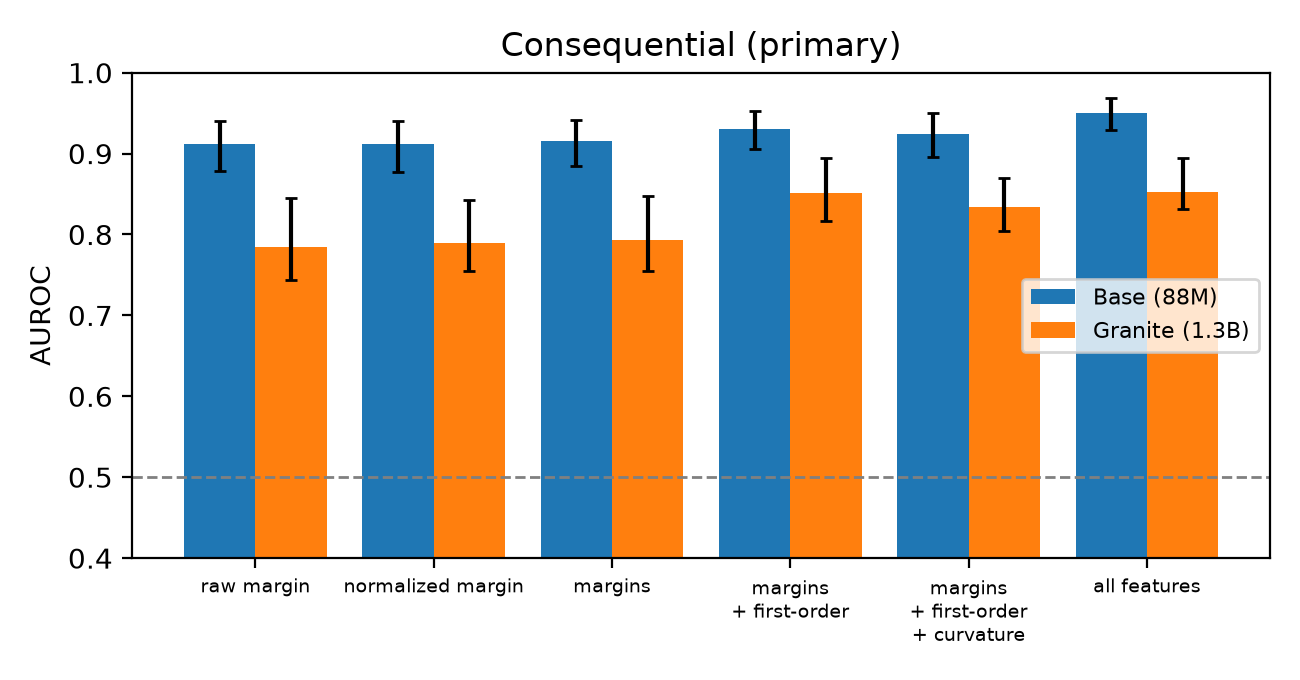

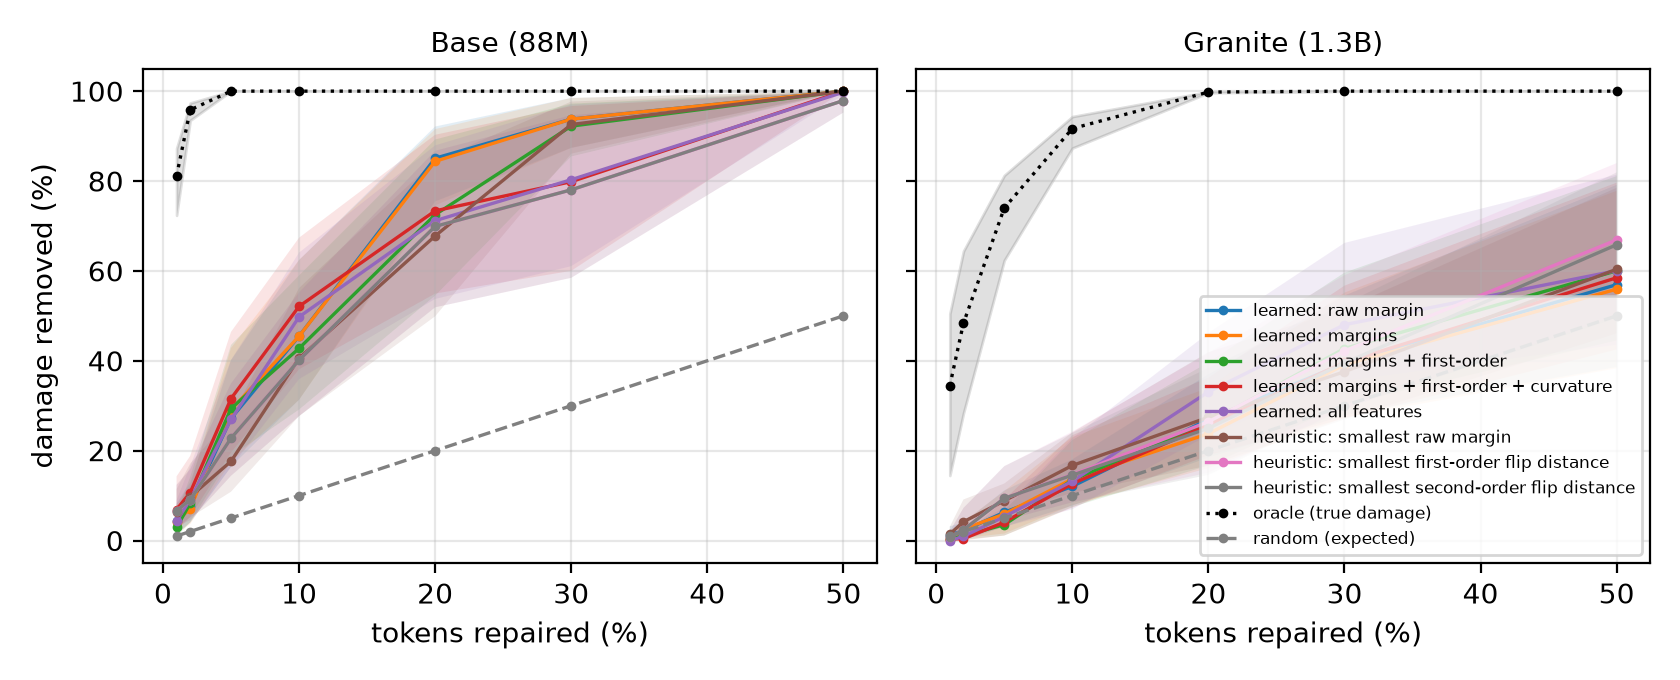

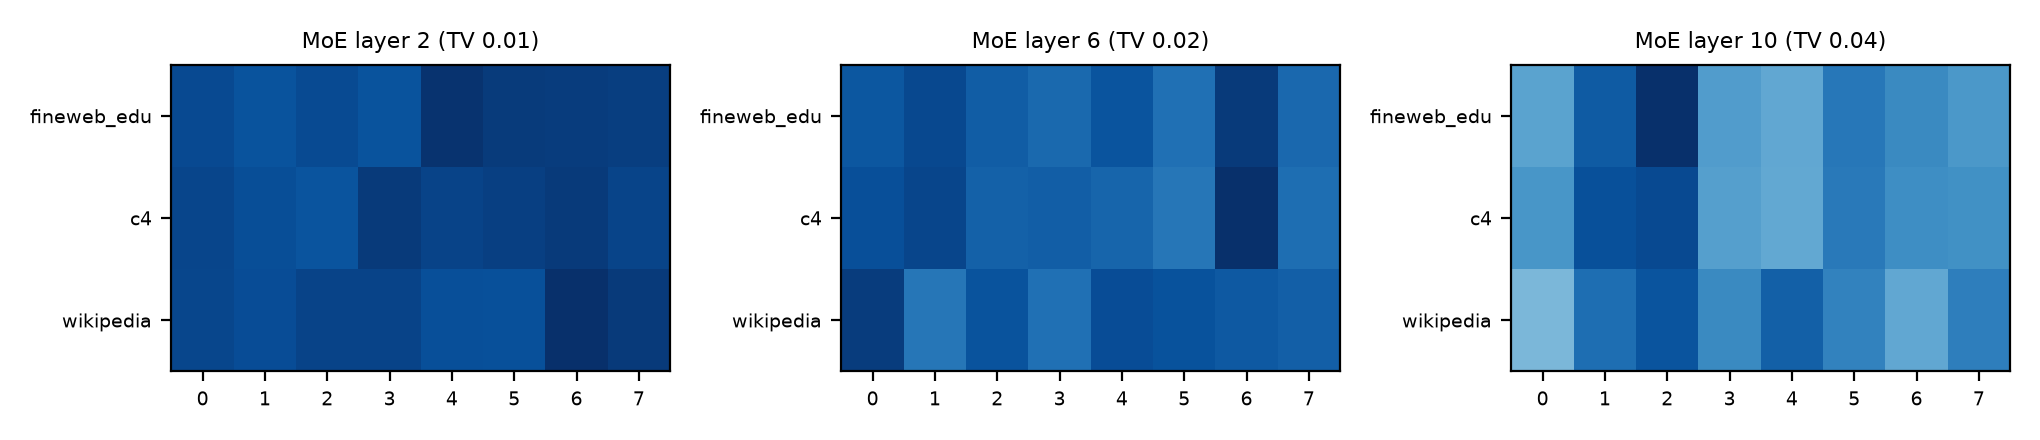

In [5]:
from IPython.display import Image, display
import os
for f in ['fig_ladder_y_consequential.png', 'fig_repair.png', 'fig_specialization.png']:
    p = '/content/drive/MyDrive/nova_base/paper/' + f
    if os.path.exists(p): display(Image(p))